# Modelado Predictivo: Clasificación con Gradient Boosting
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI)

**Contexto:** Siguiendo la arquitectura modular del proyecto (`X_features.csv` y `y_target.csv`), este notebook implementa y evalúa un clasificador **Gradient Boosting Multiclase** construido desde cero con ayuda del curso 'Machine_Learning_desde_Cero-11' del Prof. Zucco. 

A diferencia de Random Forest (que entrena árboles profundos e independientes en paralelo mediante *Bagging*), Gradient Boosting construye un ensamble **secuencial y aditivo** de árboles de regresión débiles (`RegressionTree` de poca profundidad). Cada nuevo conjunto de árboles aprende a predecir y corregir los **pseudo-residuos de probabilidad** (el gradiente negativo de la función de pérdida de entropía cruzada multiclase con activación *Softmax*) dejados por las iteraciones anteriores.

### Objetivos del Modelado

1. **Entrenamiento Secuencial Aditivo:** Entrenar un modelo `GradientBoostingClassifier` optimizando la tasa de aprendizaje (`learning_rate`), el número de etapas de boosting (`n_estimators`) y la profundidad de los árboles base (`max_depth`).

2. **Análisis de Evolución por Etapas (`staged_predict`):** Evaluar cómo evoluciona la exactitud y el Macro F1-Score a medida que se agregan árboles al ensamble, verificando la convergencia y descartando sobreajuste (*overfitting*).

3. **Evaluación Clínica Comparativa:** Medir el desempeño por clase mediante la Matriz de Confusión, Recall y F1-Score bajo la misma partición de datos (`seed=42`) utilizada en Random Forest para realizar una comparativa directa y justa.

In [1]:
# Importación de librerías 

import os # Gestión de Carpetas
import sys # Config del sistema
import numpy as np # Matemáticas
import pandas as pd # Tablas
import matplotlib.pyplot as plt # Grafico

# Modificación para importar los módulos fuera de la carpeta actual

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importamos el clasificador Gradient Boosting y nuestras utilidades

from src.GradientBoosting import GradientBoostingClassifier
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, precision, recall, f1_score

In [2]:
# Carga directa de matrices X & y generadas en 02_EDA_Visualizacion
X_df = pd.read_csv('../data/processed/X_features.csv')
y_df = pd.read_csv('../data/processed/y_target.csv')

X = X_df.to_numpy()
y = y_df['NSP'].to_numpy().ravel().astype(int)

# Partición de datos (80% entrenamiento, 20% prueba) con seed=42 para comparación directa con Random Forest
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, seed=42)

# Visualización de control
display(X_df.head())
print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP):    {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {np.unique(y)}")

,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,ALTV,...,Width,Min,Max,Nmax,Nzeros,Mode,Mean,Median,Variance,Tendency
0,120.0,0.000000,0.0,0.000000,0.000000,0.0,0.0,73.0,0.5,43.0,...,64.0,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0
1,132.0,0.006380,0.0,0.006380,0.003190,0.0,0.0,17.0,2.1,0.0,...,130.0,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0
2,133.0,0.003322,0.0,0.008306,0.003322,0.0,0.0,16.0,2.1,0.0,...,130.0,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0
3,134.0,0.002561,0.0,0.007682,0.002561,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0
4,132.0,0.006515,0.0,0.008143,0.000000,0.0,0.0,16.0,2.4,0.0,...,117.0,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0


Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP):    (2126,)
Entrenamiento: X_train=(1700, 21), y_train=(1700,)
Prueba:        X_test=(426, 21), y_test=(426,)
Clases en y:   [1 2 3]


#### **Entrenamiento de ( GradientBoostingClassifier )**

In [3]:
# Configuración de hiperparámetros del modelo
n_estimators = 100   # Número de etapas secuenciales de boosting
learning_rate = 0.1  # Tasa de aprendizaje (shrinkage)
max_depth = 3        # Árboles cortos para evitar sobreajuste

gb_model = GradientBoostingClassifier(
    n_estimators=n_estimators,
    learning_rate=learning_rate,
    max_depth=max_depth
)

gb_model.fit(X_train, y_train)

# Evaluación sobre el conjunto de entrenamiento
train_preds = gb_model.predict(X_train)
train_accuracy = accuracy(y_train, train_preds)

print("\n--Resultados de Rendimiento en Entrenamiento--")
print(f"Etapas entrenadas (n_estimators):   {len(gb_model.trees_)} etapas ({len(gb_model.trees_) * gb_model.n_classes_} árboles en total)")
print(f"Exactitud Global en Entrenamiento:  {train_accuracy * 100:.2f}%")


--Resultados de Rendimiento en Entrenamiento--
Etapas entrenadas (n_estimators):   100 etapas (300 árboles en total)
Exactitud Global en Entrenamiento:  96.18%


#### **Prueba y Evolución por Etapas ( staged_predict )**

In [ ]:
# Predicción final sobre el conjunto de prueba
test_preds = gb_model.predict(X_test)
test_accuracy = accuracy(y_test, test_preds)

# Ajuste de etiquetas (1, 2, 3 -> 0, 1, 2) para indexar la matriz de confusión
clases_unicas = np.unique(y_test)
y_real_test = (y_test - clases_unicas[0]).astype(int)
y_pred_test = (test_preds - clases_unicas[0]).astype(int)
n_classes = gb_model.n_classes_

# Cálculo de matriz y métricas por clase
matriz = confusion_matrix(y_real_test, y_pred_test, n_classes)
precisions = precision(matriz)
recalls = recall(matriz)
f1s = f1_score(matriz)

print("\n--Resultado de Rendimiento en Prueba--")
print(f"Exactitud Global en Prueba:  {test_accuracy * 100:.2f}%")

print("\n--Métricas detalladas por Clase--")
nombres_clases = ["1 (Normal)", "2 (Sospechoso)", "3 (Patológico)"]
for i, nombre in enumerate(nombres_clases):
    print(f"Clase {nombre:14s} -> Precision: {precisions[i]*100:.2f}% | Recall: {recalls[i]*100:.2f}% | F1-Score: {f1s[i]*100:.2f}%")

print(f"\nPromedio Macro F1-Score: {np.mean(f1s)*100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(matriz)


--Resultado de Rendimiento en Prueba--
Exactitud Global en Prueba:  93.43%

--Métricas detalladas por Clase--
Clase 1 (Normal)     -> Precision: 94.03% | Recall: 98.81% | F1-Score: 96.36%
Clase 2 (Sospechoso) -> Precision: 90.57% | Recall: 73.85% | F1-Score: 81.36%
Clase 3 (Patológico) -> Precision: 90.48% | Recall: 73.08% | F1-Score: 80.85%

Promedio Macro F1-Score: 86.19%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[331   3   1]
 [ 16  48   1]
 [  5   2  19]]


¿Coincide última etapa con predict?: True


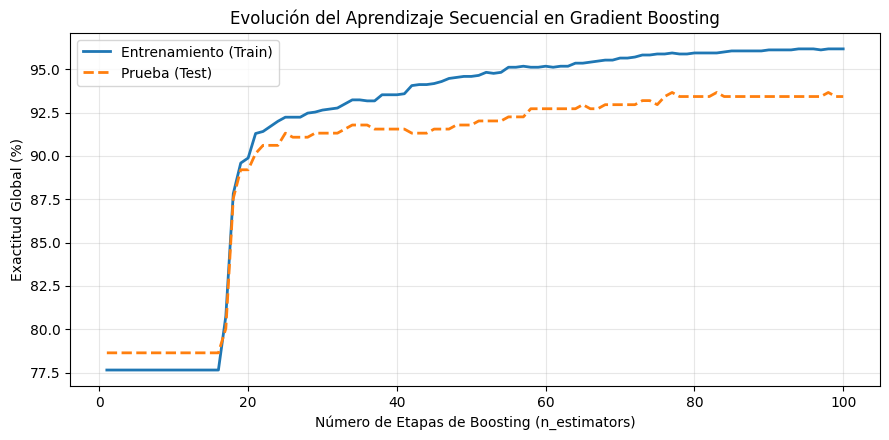

In [ ]:
# Auditoría de convergencia por etapa usando staged_predict
train_stages = gb_model.staged_predict(X_train)
test_stages = gb_model.staged_predict(X_test)

train_acc_curve = [accuracy(y_train, p) * 100 for p in train_stages]
test_acc_curve = [accuracy(y_test, p) * 100 for p in test_stages]

# Verificación de consistencia sugerida en GradientBoosting.py
print(f"¿Coincide última etapa con predict?: {np.all(test_stages[-1] == test_preds)}")

# Gráfica de evolución
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, n_estimators + 1), train_acc_curve, label='Entrenamiento (Train)', linewidth=2)
plt.plot(range(1, n_estimators + 1), test_acc_curve, label='Prueba (Test)', linewidth=2, linestyle='--')
plt.xlabel('Número de Etapas de Boosting (n_estimators)')
plt.ylabel('Exactitud Global (%)')
plt.title('Evolución del Aprendizaje Secuencial en Gradient Boosting')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Análisis y Conclusiones Finales del Modelo (Gradient Boosting vs. Random Forest)

El entrenamiento y evaluación del clasificador **Gradient Boosting Multiclase** nos permitió observar de forma práctica cómo la arquitectura matemática de un ensamble impacta directamente en el diagnóstico clínico frente a datos desbalanceados. A través de la auditoría por etapas con `staged_predict`, comprobamos el comportamiento secuencial del algoritmo: durante las primeras 16 iteraciones, la exactitud se mantuvo estática alrededor del 78% debido a que la predicción base inicial (`_initial_prediction`) parte del logaritmo de las proporciones originales del dataset, donde el 77.85% de los casos son Normales (Clase 1). Fue a partir de la etapa 17 cuando la acumulación aditiva de los árboles de regresión sobre los pseudo-residuos ($Y_{\text{onehot}} - \text{Softmax}(F)$), regulada por una tasa de aprendizaje de `0.1` y una profundidad máxima de `3` niveles, logró vencer la inercia de la clase mayoritaria y disparar la exactitud global por encima del 93% sin presentar sobreajuste (*overfitting*).

Al evaluar el modelo sobre el conjunto de prueba, el Gradient Boosting alcanzó una **Exactitud Global de 93.43%**, superando el 92.72% obtenido previamente con Random Forest. Sin embargo, el desglose por clase y la matriz de confusión revelan una lección fundamental de ciencia de datos aplicada a la medicina: **una mayor exactitud global no equivale a un mejor desempeño clínico**. Debido a que esta implementación de Gradient Boosting opera sobre la distribución natural del dataset (a diferencia del muestreo *Bootstrap* balanceado que implementamos en Random Forest), el modelo resultó ser altamente conservador y favoreció a la clase mayoritaria, logrando un impresionante Recall de 98.81% y un F1-Score de 96.36% en fetos Normales (acertando 331 de 335 casos sanos).

El costo de esta alta especificidad en pacientes sanos se reflejó en la sensibilidad hacia las clases minoritarias. En la Clase 2 (Sospechoso), el Recall se ubicó en 73.85% (con una Precisión de 90.57% y un F1-Score de 81.36%), mientras que en la Clase 3 (Patológico) el Recall fue de 73.08% (detectando 19 de los 26 casos críticos, dejando 2 como sospechosos y 5 como falsos negativos normales), situando el Promedio Macro F1-Score en **86.19%**. No obstante, destaca que la **Precisión** en la clase Patológica alcanzó un sobresaliente **90.48%** (19 aciertos de 21 alertas emitidas). 

En conclusión, la comparativa entre ambos modelos demuestra un claro compromiso (*trade-off*) diagnóstico: mientras que **Random Forest con muestreo balanceado** se posiciona como la mejor herramienta de **tamizaje preventivo** al maximizar la sensibilidad en casos patológicos (Recall de 84.62% y Macro F1 de 87.92%) para que ningún bebé en riesgo de hipoxia pase desapercibido, **Gradient Boosting** actúa como un clasificador de **alta certeza confirmatoria**, donde cada alerta patológica emitida tiene más de un 90% de probabilidad de corresponder a una emergencia real.